# PHÂN TÍCH DỮ LIỆU CHO THUÊ CĂN HỘ
- Họ Tên: Đoàn Minh Huy
- MSSV: 24700701

## 1. Giới thiệu đề tài
### 1.1. Bối cảnh và lý do chọn đề tài
Dữ liệu căn hộ cho thuê chứa nhiều thông tin như giá thuê, số phòng ngủ, số phòng tắm và vị trí. Việc phân tích dữ liệu giúp khám phá đặc điểm các căn hộ và mối quan hệ giữa giá thuê và những thuộc tính liên quan

Đề tài sử dụng bộ dữ liệu Apartments for Rent Classified ARC từ UCI Machine Learning Reposity nhằm thực hành quy trình phân tích dữ liệu bằng ipynb, bao gồm khám phá, làm sạch, thống kê, trực quan hóa và áp dụng các thuật toán.

### 1.2. Mục tiêu
- Tìm hiểu cấu trúc và các thuộc tính của bộ dữ liệu căn hộ cho thuê
- Kiểm tra, làm sạch và xử lý các vấn đề trong dữ liệu
- Thực hiện thống kê mô tả và trực quan hóa để tìm hiểu đặc điểm, sự phân bố và mối quan hệ giữa các thuộc tính
- Áp dụng các phương pháp thống kê và thuật toán cơ bản đã học
- Nhận xét, đánh giá kết quả phân tích và rút ra kết luận từ dữ liệu

## 2. Tổng quan và khám phá dữ liệu
### 2.1. Giới thiệu bộ dữ liệu Apartment for Rent
Bộ dữ liệu Apartment for Rent hay chính xác hơn là Apartment for Rent Classified là một bộ dữ liệu và các tin cho thuê nhà và căn hộ tại Mỹ. Bộ dữ liệu trên được em lấy từ UCI, một trang web có mã nguồn dataset mở, được đóng góp vào 25/12/2019. Bộ dữ liệu có 22 thuộc tính và khoảng 100000 bản ghi.

Với AFRC, em tập trung tìm hiểu đăc điểm của các căn hộ cho thuê, phân tích sự phân bố giá thuê và mối quan hệ giữa giá thuê với các thuộc tính liên quan. 

Nguồn: [AFRC Dataset](https://archive.ics.uci.edu/dataset/555/apartment+for+rent+classified)

### 2.2. Mô tả cấu trúc dữ liệu
Dataset gồm 22 thuộc tính, chia thành bốn nhóm chính.
1. Thông tin đăng ký: id, category, title, body, source, time
2. Thông tin căn hộ: square_feet, bedrooms, bathrooms, amenities, pets_allowed, has_photo
3. Thông tin giá thuê: price, price_display, price_type, currency, fee
4. Thông tin vị trí: address, cityname, state, latitude, longtitude

Các thuộc tính có cả kiểu dữ liệu số và chuỗi. Price sẽ là thuộc tính chính để tìm hiểu mối quan hệ giữa giá thuê với diện tích, số phòng, vị trí,...

### 2.3. Sơ đồ thực thể – liên kết (ERD)
Với dataset AFRC, em xây dựng ERD rồi 3 thực thể
1. THONGTINCANHO: Lưu thông tin về căn hộ
2. DIADIEM: Lưu thông tin thành phố hoặc địa điểm của căn hộ
3. NGUONTIN: Lưu thông tin nguồn đăng tin của căn hộ

Thực thể được liên kết thông qua PK và FK với hai mỗi quan hệ 1-n

![ERD của AFRC](../image/erdAFRC.png.png)

Giải thích:
Quan hệ 1: DIADIEM - THONGTINCANHO 1 - 0..n
- Một địa điểm có thể có nhiều tin đăng cho thuê
- Mỗi tin đăng thuộc một địa điểm trong mô hình.
- Liên kết bằng location_id

Quan hệ 2:
- Mọi nguồn đăng tin có thể cung cấp nhiều tin được đăng
- Mỗi tin đăng được gắn với một nguồn
- Liên kết bằng source_id

Em có bổ sung thêm 3 thuộc tính là listing_key, location_key và source_id để làm thuộc tính định danh và chỉ tồn tại trên ERD, không có sẵn trong dataset gốc.

### 2.4. Nạp dữ liệu vào Pandas
Sử dụng thư viện để đọc dataset từ file CSV và hiển thị vài dòng dữ liệu đầu để kiểm tra dữ liệu đã được nạp.

In [2]:
import pandas as pd

df = pd.read_csv(
    "../data/raw/apartments_for_rent_classified_100K.csv",
    sep=";",
    encoding="cp1252",
    low_memory=False
)

display(df.head())

,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,...,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source,time
0,5668640009,housing/rent/apartment,One BR 507 & 509 Esplanade,"This unit is located at 507 & 509 Esplanade, R...",NaN,1.0,1.0,USD,No,Thumbnail,...,"$2,195",Monthly,542,507 509 Esplanade,Redondo Beach,CA,33.8520,-118.3759,RentLingo,1577360355
1,5668639818,housing/rent/apartment,Three BR 146 Lochview Drive,"This unit is located at 146 Lochview Drive, Ne...",NaN,1.5,3.0,USD,No,Thumbnail,...,"$1,250",Monthly,1500,146 Lochview Dr,Newport News,VA,37.0867,-76.4941,RentLingo,1577360340
2,5668639686,housing/rent/apartment,Three BR 3101 Morningside Drive,This unit is located at 3101 Morningside Drive...,NaN,2.0,3.0,USD,No,Thumbnail,...,"$1,395",Monthly,1650,3101 Morningside Dr,Raleigh,NC,35.8230,-78.6438,RentLingo,1577360332
3,5668639659,housing/rent/apartment,Two BR 209 Aegean Way,"This unit is located at 209 Aegean Way, Vacavi...",NaN,1.0,2.0,USD,No,Thumbnail,...,"$1,600",Monthly,820,209 Aegean Way,Vacaville,CA,38.3622,-121.9712,RentLingo,1577360330
4,5668639374,housing/rent/apartment,One BR 4805 Marquette NE,"This unit is located at 4805 Marquette NE, Alb...",NaN,1.0,1.0,USD,No,Thumbnail,...,$975,Monthly,624,4805 Marquette NE,Albuquerque,NM,35.1038,-106.6110,RentLingo,1577360308


**Nhận xét**: Dữ liệu đã được đẩy vào DataFrame thành công. Kêt quả hiển thị 5 dòng đầu tiên với 22 thuộc tính bao gồm thông tin đăng, giá thuê,... .

### 2.5. Khám phá thông tin tổng quan
Sau khi đã có dữ liệu, kiểm tra kích thước, tên thuộc tính, kiểu dữ liệu và các thông tin thống kê cơ bản của dữ liệu.

#### Kiểm tra kích thước và tên thuộc tính

In [3]:
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])
print("Danh sách thuộc tính:")
print(df.columns.tolist())

Số dòng: 99492
Số cột: 22
Danh sách thuộc tính:
['id', 'category', 'title', 'body', 'amenities', 'bathrooms', 'bedrooms', 'currency', 'fee', 'has_photo', 'pets_allowed', 'price', 'price_display', 'price_type', 'square_feet', 'address', 'cityname', 'state', 'latitude', 'longitude', 'source', 'time']


#### Xem cấu trúc và kiểu dữ liệu

In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 99492 entries, 0 to 99491
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             99492 non-null  int64  
 1   category       99492 non-null  str    
 2   title          99492 non-null  str    
 3   body           99492 non-null  str    
 4   amenities      83448 non-null  str    
 5   bathrooms      99429 non-null  float64
 6   bedrooms       99368 non-null  float64
 7   currency       99492 non-null  str    
 8   fee            99492 non-null  str    
 9   has_photo      99492 non-null  str    
 10  pets_allowed   39068 non-null  str    
 11  price          99491 non-null  float64
 12  price_display  99491 non-null  str    
 13  price_type     99492 non-null  str    
 14  square_feet    99492 non-null  int64  
 15  address        7943 non-null   str    
 16  cityname       99190 non-null  str    
 17  state          99190 non-null  str    
 18  latitude       99

#### Thống kê cơ bản của dữ liệu

In [5]:
display(df.describe())

,id,bathrooms,bedrooms,price,square_feet,latitude,longitude,time
count,9.949200e+04,99429.000000,99368.000000,99491.000000,99492.000000,99467.000000,99467.000000,9.949200e+04
mean,5.358321e+09,1.445323,1.728212,1527.057281,956.430688,36.947988,-91.568656,1.559665e+09
std,1.847404e+08,0.547021,0.749200,904.245882,417.571522,4.599461,15.817168,1.105077e+07
min,5.121046e+09,1.000000,0.000000,100.000000,101.000000,19.573800,-159.369800,1.544174e+09
25%,5.197950e+09,1.000000,1.000000,1013.000000,729.000000,33.746500,-104.791900,1.550832e+09
50%,5.508673e+09,1.000000,2.000000,1350.000000,900.000000,37.228200,-84.562300,1.568745e+09
75%,5.509007e+09,2.000000,2.000000,1795.000000,1115.000000,39.953000,-77.608200,1.568767e+09
max,5.669439e+09,9.000000,9.000000,52500.000000,50000.000000,64.833200,-68.778800,1.577391e+09


**Nhận xét:**
- Bộ dữ liệu có 99492 bản ghi và 22 thuộc tính, gồm 5 thuộc tính float64, 3 thuộc tính int64 và 14 thuộc tính str
- Một số thuộc tính còn giá trị thiếu như amenities, pets_allowed, address, bathrooms, bedrooms, và vị trí, trong đó address và pets_allowed có số lượng giá trị thiếu khá lớn.
- Giá thuê (price) trung bình khoảng 1.527 USD, trung vị là 1.350 USD. Giá thuê thấp nhất là 100 USD và cao nhất là 52.500 USD.
- Diện tích (square_feet) trung bình khoảng 956 ft^2, trung vị là 900 ft^2 . Số phòng ngủ trung bình khoảng 1,73 và số phòng tắm trung bình khoảng 1,45.
- Từ ở phần thống kê cơ bản có thể thấy có một sự chênh lệch lớn của tiền thuê giữa căn hộ có diện tích lớn và nhỏ

### 2.6. Truy vấn dữ liệu có điều kiện
Sử dụng các lệnh để lọc và sắp xếp dữ liệu theo một số điều kiện nhằm xem thông tin các tin đăng thỏa mãn yêu cầu.

#### Lọc theo một điều kiện
Hiển thị các tin đăng có 2 phòng ngủ.

In [6]:
df_2_bedrooms = df.loc[
    df["bedrooms"] == 2,
    ["id", "cityname", "state", "bedrooms", "square_feet", "price"]
]

print("Số tin đăng có 2 phòng ngủ:", len(df_2_bedrooms))
display(df_2_bedrooms.head(10))

Số tin đăng có 2 phòng ngủ: 45975


,id,cityname,state,bedrooms,square_feet,price
3,5668639659,Vacaville,CA,2.0,820,1600.0
5,5668639368,Albuquerque,NM,2.0,965,1250.0
6,5668638765,Hampton,VA,2.0,1120,1600.0
7,5668638578,Lakewood,CO,2.0,947,1300.0
8,5668638476,Charleston,WV,2.0,600,795.0
9,5668638122,Chatsworth,CA,2.0,1005,2150.0
11,5668637998,Marblehead,MA,2.0,3077,3195.0
12,5668637809,Washington,DC,2.0,896,2395.0
15,5668636381,Kirkland,WA,2.0,872,2000.0
19,5668633909,Portland,OR,2.0,435,1250.0


#### Lọc thoe nhiều điều kiện
Tìm các tin đăng có giá thuê từ 1000 USD đến 2000 USD trên một tháng

In [7]:
df_price_range = df.loc[
    (df["price"] >= 1000) &
    (df["price"] <= 2000) &
    (df["currency"] == "USD") &
    (df["price_type"] == "Monthly"),
    ["id", "cityname", "state", "price", "currency",
     "price_type", "square_feet"]
]

print("Số tin đăng thỏa điều kiện:", len(df_price_range))
display(df_price_range.head(10))

Số tin đăng thỏa điều kiện: 57968


,id,cityname,state,price,currency,price_type,square_feet
1,5668639818,Newport News,VA,1250.0,USD,Monthly,1500
2,5668639686,Raleigh,NC,1395.0,USD,Monthly,1650
3,5668639659,Vacaville,CA,1600.0,USD,Monthly,820
5,5668639368,Albuquerque,NM,1250.0,USD,Monthly,965
6,5668638765,Hampton,VA,1600.0,USD,Monthly,1120
7,5668638578,Lakewood,CO,1300.0,USD,Monthly,947
10,5668638015,Alpharetta,GA,1795.0,USD,Monthly,1522
15,5668636381,Kirkland,WA,2000.0,USD,Monthly,872
17,5668635018,Villa Park,IL,1045.0,USD,Monthly,700
18,5668634255,Oxford,MS,1800.0,USD,Monthly,1500


#### Sắp xếp dữ liệu
Sắp xếp các tin đã lọc theo giá thuê bên trên theo giảm dần

In [8]:
df_sorted = df_price_range.sort_values(
    by="price",
    ascending=False
)

display(df_sorted.head(10))

,id,cityname,state,price,currency,price_type,square_feet
99328,5122057036,Suwanee,GA,2000.0,USD,Monthly,2394
37197,5508842276,Braintree,MA,2000.0,USD,Monthly,1000
72,5668639731,Kent,WA,2000.0,USD,Monthly,1220
15,5668636381,Kirkland,WA,2000.0,USD,Monthly,872
58594,5198520256,Irvine,CA,2000.0,USD,Monthly,737
58589,5198521971,Naples,FL,2000.0,USD,Monthly,768
15187,5508715410,Harrison,NJ,2000.0,USD,Monthly,785
58564,5198531516,Beverly,MA,2000.0,USD,Monthly,716
15149,5508741312,Boston,MA,2000.0,USD,Monthly,1000
15137,5508747893,Boston,MA,2000.0,USD,Monthly,1000


**Nhận xét:**
1. Có 45975 tin có 2 phòng ngủ. Trong 10 dòng được hiển thị, các căn hộ có diện tích và giá thuê khác nhau tùy theo từng tin đăng
2. Có 57968 tin thỏa mãn giá thuê từ 1000 đến 2000 USD một thnags. CHo thấy nhiều tin đăng nằm trong khoảng giá được chọn
3. Sau khi sắp xếp giá thuê giảm dần, 10 dòng đầu tiên có giá thuê 2000 USD. Tuy có cùng mức giá hưng cso thể thấy diện tích và vị trí là khác nhau

### 2.7. Sắp xếp và lọc dữ liệu
Tiếp tục lọc các tin đăng theo vị trí và đặc điểm căn hộ, sau đó sắp xếp kết quả theo nhiều thuộc tính để dễ quan sát và so sánh dữ liệu

#### Lọc theo vị trí và số phòng ngủ

In [9]:
df_ca = df.loc[
    (df["state"] == "CA") &
    (df["bedrooms"] >= 2),
    ["id", "cityname", "state", "bedrooms", "square_feet", "price"]
]

print("Số tin đăng thỏa điều kiện:", len(df_ca))
display(df_ca.head(10))


Số tin đăng thỏa điều kiện: 5750


,id,cityname,state,bedrooms,square_feet,price
3,5668639659,Vacaville,CA,2.0,820,1600.0
9,5668638122,Chatsworth,CA,2.0,1005,2150.0
28,5668630836,Ladera Ranch,CA,3.0,1525,3250.0
39,5668627095,San Jose,CA,3.0,1739,3990.0
41,5668627015,Oakland,CA,2.0,860,2550.0
42,5668626906,Mission Viejo,CA,4.0,3350,4950.0
43,5668626824,Berkeley,CA,2.0,1200,4950.0
46,5668625042,Sherman Oaks,CA,2.0,1391,2548.0
61,5668615317,Sacramento,CA,2.0,572,1385.0
106,5668627070,Hawthorne,CA,2.0,1070,2200.0


#### Sắp xếp theo nhiều thuộc tính

In [10]:
df_ca_sorted = df_ca.sort_values(
    by=["bedrooms", "square_feet"],
    ascending=[True, False]
)

display(df_ca_sorted.head(10))

,id,cityname,state,bedrooms,square_feet,price
32210,5509261541,Pasadena,CA,2.0,2535,5750.0
17162,5508880768,Los Angeles,CA,2.0,2372,6400.0
39472,5508925329,Beverly Hills,CA,2.0,2330,11000.0
20827,5509043710,Santa Monica,CA,2.0,2328,5950.0
5298,5664598216,Encinitas,CA,2.0,2283,5350.0
33700,5508681886,Los Angeles,CA,2.0,2274,7920.0
16174,5508798859,Los Angeles,CA,2.0,2248,6500.0
40698,5508905079,West Hollywood,CA,2.0,2246,11500.0
77742,5197985405,Indio,CA,2.0,2147,2250.0
75580,5198008022,Beaumont,CA,2.0,2127,1800.0


**Nhận xét:**
1. Có 5750 tin tại bang CA có từ 2 phòng ngủ trở lên. Trong 10 dòng đầu tiên, số phòng ngủ, diện tích, giá thuê có sự khác nhau tùy theo căn hộ
2. Sau khi sắp xếp theo số phòng ngủ tăng dần, diện tích giảm dần, 10 dòng đầu đều có 2 phòng ngủm diện tích từ 2100 đến 2550 ft^2. Giá thuê của các căn hộ này cũng có sự chênh lệch, từ 1800 đến 11500 USD.

## 3. Tiền xử lý và làm sạch dữ liệu
### 3.1. Kiểm tra dữ liệu thiếu
Sử dụng các lệnh để kiểm tra số lượng và tỉ lệ giá trị thiếu ở từng thuộc tính. Trực quan hóa bằng biểu đồ để xác định những thuộc tính có nhiều dữ liệu thiếu

#### Kiểm tra số lượng và tỷ lệ dữ liệu thiếu

In [11]:

missing_count = df.isnull().sum()

missing_percent = (missing_count / len(df) * 100).round(2)

df_missing = pd.DataFrame({
    "Số lượng thiếu": missing_count,
    "Tỷ lệ thiếu (%)": missing_percent
})

df_missing = df_missing.sort_values(
    by="Số lượng thiếu",
    ascending=False
)

display(df_missing)

print("Số thuộc tính có dữ liệu thiếu:",
      (missing_count > 0).sum())


,Số lượng thiếu,Tỷ lệ thiếu (%)
address,91549,92.02
pets_allowed,60424,60.73
amenities,16044,16.13
cityname,302,0.30
state,302,0.30
bedrooms,124,0.12
bathrooms,63,0.06
latitude,25,0.03
longitude,25,0.03
price,1,0.00


Số thuộc tính có dữ liệu thiếu: 11


**Nhận xét:**
- Dữ liệu có 11/22 thuộc tính xuất hiện giá trị thiếu, trong khi 11 thuộc tính còn lại không thiếu
- Trong đó address có tý lệ cao nhất với 92,02%, theo sau là pets_allowed 60,73% và amenities với 16,13%
- Một số thuộc tính khác như cityname, state, bedrooms, bathrooms, latitude, longitude, price và price_display có thiếu, nhưng tỷ lệ rất thấp, dưới 1%

Nhìn chung, dữ liệu thiếu có sự chênh lệch khá lớn về tỷ lệ thiếu giữu các thuộc tính. 

### 3.2. Trực quan hóa dữ liệu thiếu


#### Biểu đồ cột ngang tỷ lệ dữ liệu thiếu

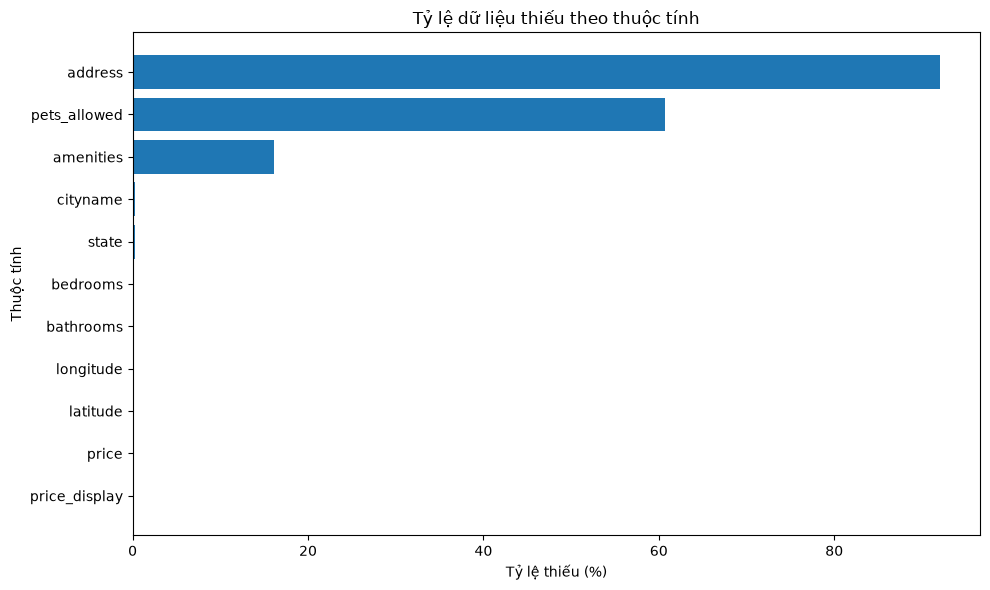

In [13]:
import matplotlib.pyplot as plt

missing_chart = df_missing[df_missing["Số lượng thiếu"] > 0]

missing_chart = missing_chart.sort_values(
    by="Tỷ lệ thiếu (%)"
)

plt.figure(figsize=(10, 6))

plt.barh(
    missing_chart.index,
    missing_chart["Tỷ lệ thiếu (%)"]
)

plt.title("Tỷ lệ dữ liệu thiếu theo thuộc tính")
plt.xlabel("Tỷ lệ thiếu (%)")
plt.ylabel("Thuộc tính")

plt.tight_layout()
plt.show()


#### Biểu đồ heatmap dữ liệu thiếu

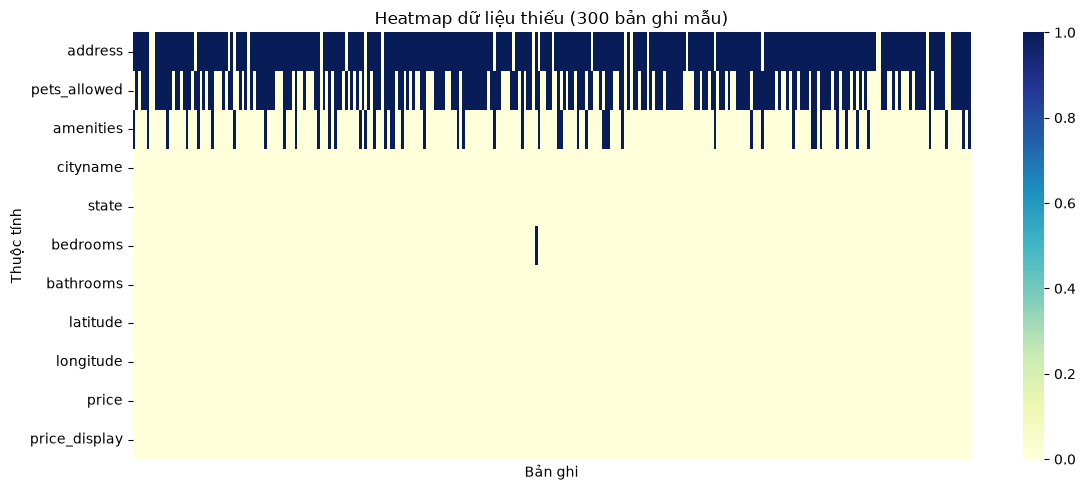

In [14]:

import seaborn as sns
import matplotlib.pyplot as plt

missing_cols = df_missing[
    df_missing["Số lượng thiếu"] > 0
].index

df_missing_sample = df[missing_cols].sample(
    n=300,
    random_state=42
)

plt.figure(figsize=(12, 5))

sns.heatmap(
    df_missing_sample.isnull().T,
    cmap="YlGnBu",
    cbar=True,
    xticklabels=False
)

plt.title("Heatmap dữ liệu thiếu (300 bản ghi mẫu)")
plt.xlabel("Bản ghi")
plt.ylabel("Thuộc tính")

plt.tight_layout()
plt.show()


**Nhận xét**
1. Biểu đồ cột ngang: Dữ liệu thiếu tập trung chủ yếu ở address với 92,02%, pets_allowed 60,73% và amenities là 16,13%. Các thuộc tính còn lại không đáng kể với dưới 1%
2. Biểu đồ heatmap: Chọn 300 bản ghi, các ô màu xanh đậm thể hiện giá trị thiếu, xuất hiện nhiều nhất ở address và pets_allowed, tiếp theo là amenities. Các thuộc tính còn lại hầu như có đầy đủ dữ liệu
- Cả hai biểu đồ cho thấy dữ liệu thiếu có phân bố không đồng đều giữa các thuộc tính.

### 3.3. Kiểm tra dữ liệu trùng lặp
Dùng các hàm để kiểm tra các bản ghi trùng lặp trong dữu liệu, bao gồm trùng lặp toàn bộ dòng dữ liệu và trùng id.

#### Kiểm tra dữ liệu trùng lặp

In [15]:
duplicate_rows = df.duplicated().sum()

print("Số bản ghi trùng hoàn toàn:", duplicate_rows)

display(df[df.duplicated(keep=False)].head(10))

Số bản ghi trùng hoàn toàn: 84


,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,...,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source,time
41914,5508806580,housing/rent/apartment,"Las Vegas, prime location Two BR, Apartment. P...",Live in the middle of it all! South is a pet f...,"Gym,Parking,Pool",2.0,2.0,USD,No,Yes,...,"$1,335",Monthly,1084,NaN,Las Vegas,NV,36.1536,-115.1965,RentDigs.com,1568754086
41915,5508806428,housing/rent/apartment,Northglenn Value. Pet OK!,"Square footage: 738 square ft, unit number: 06...","Gym,Parking,Pool,Storage",1.0,1.0,USD,No,Yes,...,"$1,331",Monthly,738,NaN,Northglenn,CO,39.8999,-104.9442,RentDigs.com,1568754072
41916,5508806391,housing/rent/apartment,Apartment in move in condition in District Hei...,Capital Courts has something for everyone. Loc...,"AC,Parking,Playground,Pool",1.5,3.0,USD,No,Yes,...,"$1,320",Monthly,943,NaN,District Heights,MD,38.8516,-76.8871,RentDigs.com,1568754069
41917,5508806299,housing/rent/apartment,"District Heights, prime location Two BR, Apart...",Income Requirement: Must have 2. 5x the rent i...,Parking,1.0,2.0,USD,No,Yes,...,"$1,349",Monthly,931,NaN,District Heights,MD,38.8516,-76.8871,RentDigs.com,1568754061
41918,5508806233,housing/rent/apartment,"Spacious One BR, One BA","Square footage: 680 sq-ft, unit number: 122. P...","Basketball,Gym,Patio/Deck,Playground,Pool",1.0,1.0,USD,No,Yes,...,"$1,260",Monthly,680,NaN,Denver,CO,39.8999,-104.9442,RentDigs.com,1568754056
41919,5508806180,housing/rent/apartment,Beautiful Thornton Apartment for rent,"Square footage: 827 sq-ft, unit number: 2034. ...","AC,Basketball,Clubhouse,Dishwasher,Fireplace,G...",1.0,1.0,USD,No,Yes,...,"$1,203",Monthly,827,NaN,Thornton,CO,39.8999,-104.9442,RentDigs.com,1568754052
41920,5508806119,housing/rent/apartment,"Bright District Heights, One BR, One BA for re...",Thanks for your interest in Rochelle Hall Apar...,Parking,1.0,1.0,USD,No,No,...,$950,Monthly,523,NaN,District Heights,MD,38.8516,-76.8871,RentDigs.com,1568754048
41921,5508806034,housing/rent/apartment,Los Angeles - 2bd/Two BA 966sqft Apartment for...,"Welcome to Cole, a newly constructed Wiseman c...",Gym,2.0,2.0,USD,No,Yes,...,"$3,095",Monthly,966,NaN,Los Angeles,CA,34.0911,-118.3430,RentDigs.com,1568754041
41922,5508805994,housing/rent/apartment,"$3,850/mo - must see to believe.","Welcome to Cole, a newly constructed Wiseman c...",Gym,3.0,3.0,USD,No,Yes,...,"$3,850",Monthly,1318,NaN,Los Angeles,CA,34.0911,-118.3430,RentDigs.com,1568754037
41923,5508805990,housing/rent/apartment,Apartment \ Two BA - ready to move in. Pet OK!,"Square footage: 1093 sq. feet, unit number: 13...","AC,Cable or Satellite,Clubhouse,Dishwasher,Fir...",2.0,2.0,USD,No,Yes,...,"$1,620",Monthly,1093,NaN,Denver,CO,39.8999,-104.9442,RentDigs.com,1568754037


#### Kiểm tra trùng id đăng

In [19]:

duplicate_ids = df["id"].duplicated().sum()

print("Số trường hợp ID trùng:", duplicate_ids)

df_duplicate_ids = df[
    df["id"].duplicated(keep=False)
].sort_values(by="id")

print(
    "ID trùng nhưng nội dung khác:",
    (df["id"].duplicated() & ~df.duplicated()).sum()
)

display(
    df_duplicate_ids[
        ["id", "title", "price", "square_feet", "cityname", "state"]
    ].head(10)
)


Số trường hợp ID trùng: 84
ID trùng nhưng nội dung khác: 0


,id,title,price,square_feet,cityname,state
79465,5195387513,Townhome like Duplex,2450.0,820,Lemon Grove,CA
83210,5195387513,Townhome like Duplex,2450.0,820,Lemon Grove,CA
83209,5197678700,This Apartment is a must see!,1489.0,983,Memphis,TN
79464,5197678700,This Apartment is a must see!,1489.0,983,Memphis,TN
79463,5197682059,"Spacious One BR, One BA",832.0,660,Olathe,KS
83208,5197682059,"Spacious One BR, One BA",832.0,660,Olathe,KS
83247,5197828778,"Two BA - $1,862/mo - Apartment - in a great ar...",1862.0,1261,Tempe,AZ
79502,5197828778,"Two BA - $1,862/mo - Apartment - in a great ar...",1862.0,1261,Tempe,AZ
79501,5197828852,The Best of the Best in the City of Tempe! Sav...,1877.0,1261,Tempe,AZ
83246,5197828852,The Best of the Best in the City of Tempe! Sav...,1877.0,1261,Tempe,AZ


**Nhận xét:**
1. Phát hiện 84 dòng trùng hoản toàn trên tất cả 22 thuộc tính của dataset
2. Có 84 dòng có id đăng trùng lặp. Từ bảng cho thấy những thông tin đăng có cùng id cugx có thông tin giống nhau về tiêu đề, giá thuê và diện tích và vị trí

### 3.4. Kiểm tra kiểu dữ liệu và định dạng
Kiểm tra kiểu dữ liệu và các giá trị của một số thuộc tính như giá thuê, đơn vị tiền, loại tin, thời gian để xác định những vấn đề về định dạng trước khi làm sạch dữ liệu

#### Kiểm tra định dạng và giá trị phân loại

In [20]:

check_columns = [
    "price", "price_display", "bedrooms",
    "bathrooms", "currency", "price_type", "time"
]

print("Kiểu dữ liệu:")
print(df[check_columns].dtypes)

display(
    df[["price", "price_display", "currency", "price_type"]].head(10)
)

print("\nĐơn vị tiền tệ:")
print(df["currency"].value_counts(dropna=False))

print("\nKỳ thanh toán:")
print(df["price_type"].value_counts(dropna=False))

print("\nLoại tin đăng:")
print(df["category"].value_counts(dropna=False))

print("\nTrạng thái hình ảnh:")
print(df["has_photo"].value_counts(dropna=False))


Kiểu dữ liệu:
price            float64
price_display        str
bedrooms         float64
bathrooms        float64
currency             str
price_type           str
time               int64
dtype: object


,price,price_display,currency,price_type
0,2195.0,"$2,195",USD,Monthly
1,1250.0,"$1,250",USD,Monthly
2,1395.0,"$1,395",USD,Monthly
3,1600.0,"$1,600",USD,Monthly
4,975.0,$975,USD,Monthly
5,1250.0,"$1,250",USD,Monthly
6,1600.0,"$1,600",USD,Monthly
7,1300.0,"$1,300",USD,Monthly
8,795.0,$795,USD,Monthly
9,2150.0,"$2,150",USD,Monthly



Đơn vị tiền tệ:
currency
USD    99492
Name: count, dtype: int64

Kỳ thanh toán:
price_type
Monthly           99488
Weekly                3
Monthly|Weekly        1
Name: count, dtype: int64

Loại tin đăng:
category
housing/rent/apartment            99431
housing/rent/commercial/retail       42
housing/rent                          7
housing/rent/home                     4
housing/rent/short_term               4
housing/rent/condo                    3
housing/rent/other                    1
Name: count, dtype: int64

Trạng thái hình ảnh:
has_photo
Yes          55974
Thumbnail    34303
No            9215
Name: count, dtype: int64


#### Kiểm tra định dạng thời gian

In [21]:

time_check = pd.to_datetime(
    df["time"],
    unit="s",
    errors="coerce",
    utc=True
)

display(pd.DataFrame({
    "time_goc": df["time"].head(10),
    "thoi_gian_UTC": time_check.head(10)
}))

print("Số giá trị thời gian không hợp lệ:",
      time_check.isna().sum())


,time_goc,thoi_gian_UTC
0,1577360355,2019-12-26 11:39:15+00:00
1,1577360340,2019-12-26 11:39:00+00:00
2,1577360332,2019-12-26 11:38:52+00:00
3,1577360330,2019-12-26 11:38:50+00:00
4,1577360308,2019-12-26 11:38:28+00:00
5,1577360308,2019-12-26 11:38:28+00:00
6,1577360261,2019-12-26 11:37:41+00:00
7,1577360247,2019-12-26 11:37:27+00:00
8,1577360239,2019-12-26 11:37:19+00:00
9,1577360204,2019-12-26 11:36:44+00:00


Số giá trị thời gian không hợp lệ: 0


**Nhận xét:**
- Kiểu dữ liệu: Các thuộc tình price, bedrooms, bathrooms có kiểu float64, price_display có kiểu chuỗi và time có kiểu int64. price_display thể hiện giá thuê dưới dạng văn bản có ký hiệu tiền tệ $ number
- Đơn vị tiền tệ và kỳ thanh toán: Toàn bộ 99.492 bản ghi sử dụng USD, phần lớn có kỳ thành toán là Monthly, có 3 bản là Weekly và 1 là Monthly|Weekly
- Loại tin: Phần lớn thuộc nhóm housing/rent/apartment, một số ít là các loại hình khác
- Trạng thái hình ảnh: Thuộc tính has_photo gồm 3 giá trị Yes, Thumbnail và No tương ứng các trạng thái hình ảnh của tin
- Định dạng thời gian: Thuộc tính tiem được lưu dưới dạng Unix timestamp và có thể chuyển đổi sang định dạng ngày giờ, kiểm tra tất cả đều hợp lệ.

### 3.5. Phát hiện giá trị bất thường
Kiểm tra các giá trị không hợp lý và sử dụng phương pháp IQR kết hợp boxplot để phát hiện những giá trị ngoại lai trong dữ liệu căn hộ cho thuê

#### Kiểm tra giá trị không hợp lý


In [22]:
print("Giá thuê <= 0:", (df["price"] <= 0).sum())
print("Diện tích <= 0:", (df["square_feet"] <= 0).sum())
print("Phòng ngủ < 0:", (df["bedrooms"] < 0).sum())
print("Phòng tắm < 0:", (df["bathrooms"] < 0).sum())

Giá thuê <= 0: 0
Diện tích <= 0: 0
Phòng ngủ < 0: 0
Phòng tắm < 0: 0


#### Phát hiện outlier bằng IQR
Chỉ chọn các tin căn hộ sử dụng USD và có kỳ thanh toán theo tháng để so sánh giá thuê hợp lý.

In [23]:
df_apartment = df[
    (df["category"] == "housing/rent/apartment") &
    (df["currency"] == "USD") &
    (df["price_type"] == "Monthly")
]

columns = ["price", "square_feet"]

results = []

for col in columns:
    Q1 = df_apartment[col].quantile(0.25)
    Q3 = df_apartment[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (
        (df_apartment[col] < lower) |
        (df_apartment[col] > upper)
    )

    results.append({
        "Thuộc tính": col,
        "Ngưỡng dưới": round(lower, 2),
        "Ngưỡng trên": round(upper, 2),
        "Số outlier": outliers.sum()
    })

display(pd.DataFrame(results))

,Thuộc tính,Ngưỡng dưới,Ngưỡng trên,Số outlier
0,price,-160.0,2968.0,4695
1,square_feet,150.0,1694.0,2840


Phương phá IQR sử dụng hai tứ phân vị Q1 và Q3 với công thức: IQR=Q3-Q1

Các giá trị nhỏ hơn Q1 - 1,5 * IQR hoặc lớn hơn Q3 + 1,5 * IQR được xem là outlier. 


#### Trực quan hóa bằng Boxplot

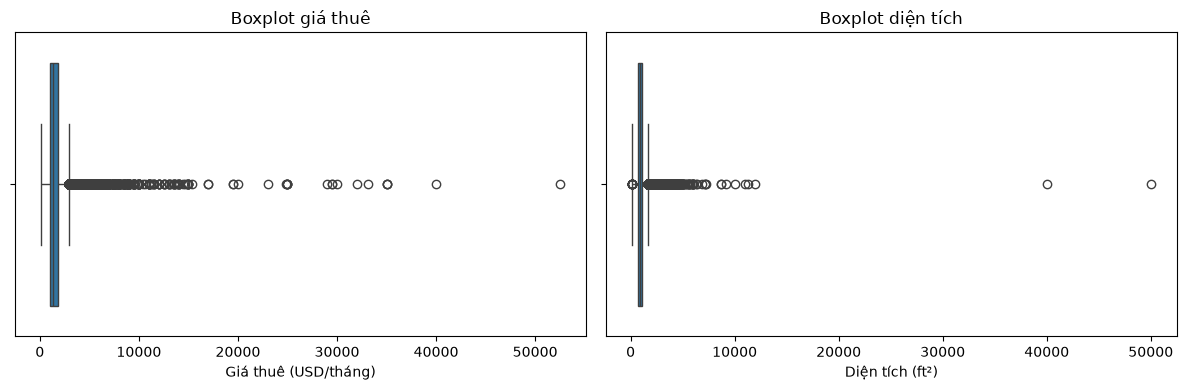

In [25]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(
    x=df_apartment["price"],
    ax=axes[0]
)
axes[0].set_title("Boxplot giá thuê")
axes[0].set_xlabel("Giá thuê (USD/tháng)")

sns.boxplot(
    x=df_apartment["square_feet"],
    ax=axes[1]
)
axes[1].set_title("Boxplot diện tích")
axes[1].set_xlabel("Diện tích (ft²)")

plt.tight_layout()
plt.show()


**Nhận xét:**
1. Không phát hiện giá thuê, diện tích, bedroom và bathroom có giá trị bất thường
2. Với IQR, price có 4.695 giá trị ngoại lại nằm ngoài -160 đến 2968 USD. square_feet cso 2840 giá trị ngoài lai, khoảng 150 đến 1694 ft^2
3. Hai biểu đồ boxplot cho thấy phần lớn giá thuê và diện tích tập trung trong một khoảng tương đối hẹp, trong khi nhiều điểm ngoại lai nằm xa về phía giá trị lớn. Một số tin có giá lên tận 50000 USD và diên tích khoảng 50000 ft^2
- Nhìn chung dữ liệu có nhiều gia trị ngoại lai ở thuộc tính giá thuê và diện tích.

### 3.6. Xử lý dữ liệu và kiểm tra kết quả
Dựa trên các kết quả kiểm tra ở các mục trước, thực hiện loại bỏ những bản ghi trùng lặp, giới hạn dữ liệu trong phạm vi căn hộ cho thuê theo tháng và xử lý giá trị thiếu ở thuộc tính giá thuê.

Các thuộc tính thiếu thông tin và giá trị ngoại lai khác được giữ lại để tránh làm mất dữ liệu vì một số chiếm phần lớn.

#### Loại bỏ các bản ghi trùng hoàn toàn

In [26]:
df_clean = df.copy()

rows_before = len(df_clean)

df_clean = df_clean.drop_duplicates().copy()

print("Số bản ghi ban đầu:", rows_before)
print("Số bản ghi trùng đã loại bỏ:",
      rows_before - len(df_clean))
print("Số bản ghi còn lại:", len(df_clean))

Số bản ghi ban đầu: 99492
Số bản ghi trùng đã loại bỏ: 84
Số bản ghi còn lại: 99408


#### Lọc dữ liệu theo phạm vi và xử lý giá thuê thiếu
Vì bài được em xác định tập trung vào căn hộ cho thuê và giá theo tháng nên giới hạn dữ liệu theo điều kiện

In [27]:
rows_before = len(df_clean)

df_clean = df_clean.loc[
    (df_clean["category"] == "housing/rent/apartment") &
    (df_clean["price_type"] == "Monthly")
].copy()

print("Số bản ghi ngoài phạm vi đã loại bỏ:",
      rows_before - len(df_clean))

rows_before = len(df_clean)

df_clean = df_clean.dropna(subset=["price"]).copy()

print("Số bản ghi thiếu giá thuê đã loại bỏ:",
      rows_before - len(df_clean))

df_clean = df_clean.reset_index(drop=True)

print("Số bản ghi sau xử lý:", len(df_clean))

Số bản ghi ngoài phạm vi đã loại bỏ: 65
Số bản ghi thiếu giá thuê đã loại bỏ: 1
Số bản ghi sau xử lý: 99342


#### Kiểm tra kết quả sau khi làm sạch

In [28]:
print("Dữ liệu gốc:", df.shape)
print("Dữ liệu sau làm sạch:", df_clean.shape)

print("Bản ghi trùng hoàn toàn:",
      df_clean.duplicated().sum())

print("ID trùng:",
      df_clean["id"].duplicated().sum())

print("Giá thuê bị thiếu:",
      df_clean["price"].isnull().sum())

print("Tin đăng không thuộc loại căn hộ:",
      (df_clean["category"] != "housing/rent/apartment").sum())

print("Kỳ thanh toán không phải Monthly:",
      (df_clean["price_type"] != "Monthly").sum())

print("Số thuộc tính còn giá trị thiếu:",
      (df_clean.isnull().sum() > 0).sum())


Dữ liệu gốc: (99492, 22)
Dữ liệu sau làm sạch: (99342, 22)
Bản ghi trùng hoàn toàn: 0
ID trùng: 0
Giá thuê bị thiếu: 0
Tin đăng không thuộc loại căn hộ: 0
Kỳ thanh toán không phải Monthly: 0
Số thuộc tính còn giá trị thiếu: 9


**Nhận xét:**
1. Đã loại bỏ 84 dòng trùng hoàn toàn, số dòng giảm từ 99492 xuống còn 99408
2. Tiếp tục loại bỏ 65 bản ghi không thuộc phạm vi căn hộ cho thuê theo tháng và 1 bản ghi thieus giá thêu. Dữ liệu còn 99342 bản ghi
3. Kết quả kiểm tra cho thấy không còn bản ghi trùng hoàn toàn, id trùng lặp, giá thiếu hoặc tin không thuộc phạm vi cho thuê. Số thuộc tính vẫn là 22
- Dữ liệu vẫn còn 9 thuộc tính có giá trị thiếu. Các giá trị này được giữ lại vì em tránh làm mất thông tin khi một số có số lượng quá lớn.

## 4. Thống kê mô tả và trực quan hóa dữ liệu
### 4.1. Các đại lượng đo xu hướng trung tâm
### 4.2. Các đại lượng đo độ phân tán
### 4.3. Độ lệch và độ nhọn của phân phối
### 4.4. Các biểu đồ thống kê dữ liệu

## 5. Phân phối xác suất
### 5.1. Phân phối nhị thức (Binomial)
### 5.2. Phân phối Poisson

## 6. Kiểm định giả thuyết thống kê
### 6.1. Kiểm định T-Test
### 6.2. Kiểm định Z-Test

## 7. Hiệp phương sai, tương quan và hồi quy tuyến tính
### 7.1. Hiệp phương sai (Covariance)
### 7.2. Hệ số tương quan (Correlation)
### 7.3. Hồi quy tuyến tính (Linear Regression)
### 7.4. Đánh giá mô hình hồi quy

## 8. Học máy có giám sát
### 8.1. Hồi quy Logistic (Logistic Regression)
### 8.2. Phân loại Naive Bayes

## 9. Phân cụm và luật kết hợp
### 9.1. Phân cụm K-Means
### 9.2. Luật kết hợp (Association Rules)

## 10. Cây quyết định và PCA
### 10.1. Cây quyết định (Decision Tree)
### 10.2. Phân tích thành phần chính (PCA)

## 11. Kết luận
### 11.1. Tổng hợp kết quả
### 11.2. Hạn chế